# **Estimación de la frecuencia cardiaca de una señal ECG**
## **Proyecto Tratamiento de Señales Discretas 2026-2 · Grupo 08**

**Idea base:** uso el algoritmo de **Pan y Tompkins (1985)**. Primero limpio la señal con filtros y después busco los picos R, que son las puntas más altas y rápidas de cada latido. Con el tiempo entre picos (intervalo RR) calculo la frecuencia cardiaca:
$$FC = \frac{60}{\overline{RR}}\ \text{[lpm]}$$

**Pasos del código:**
1. Elijo una o varias señales y las cargo.
2. Miro su espectro (FFT) para ver qué ruido tiene.
3. Quito el ruido de la red eléctrica con un filtro **notch**.
4. Dejo solo la banda del QRS con un filtro **pasa-banda de 5 a 15 Hz**.
5. Resalto los QRS con **derivada, cuadrado e integración** (Pan y Tompkins).
6. Detecto los **picos R**.
7. Calculo los intervalos **RR** y la **FC**.
8. *(Opcional)* Repito todo para las 48 señales y genero `resultados_g08.csv`.

> **Para la comprobación del profesor solo hay que cambiar la lista `SENALES` en el Paso 0** (por ejemplo `SENALES = [14]` o `SENALES = [3, 14, 41]`) **y ejecutar todo** (menú *Run All* / *Ejecutar todo*).

## **Paso 0 – Elegir la(s) señal(es)**
**Qué hace:** aquí escribo los números de las señales que quiero analizar (de 1 a 48), separados por comas dentro de los corchetes. **Es lo único que hay que modificar.**
- Una señal: `SENALES = [14]`
- Varias señales: `SENALES = [3, 14, 41]`

Todos los pasos siguientes se repiten automáticamente para cada señal de la lista.

In [1]:
SENALES = [3, 41]       # <<< CAMBIAR AQUÍ: número(s) de la(s) señal(es) que da el profesor (1 a 48)
CARPETA = "data"      # carpeta donde están los archivos senal_XX.csv

## **Paso 1 – Cargar cada señal y graficarla**
**Qué hace:** leo el archivo `senal_XX.csv` (columnas `tiempo_s` y `ecg_mV`) y calculo la frecuencia de muestreo a partir del tiempo: $f_s = 1/\Delta t$. Así el código funciona igual con las señales de 360 Hz y con las de 90 Hz, sin escribir la $f_s$ a mano. Guardo todo lo de cada señal en el diccionario `S`.

**Qué muestra:** cada señal original tal como viene, con todo su ruido.

Señal 3: fs = 360 Hz, 10800 muestras, duración = 30.0 s


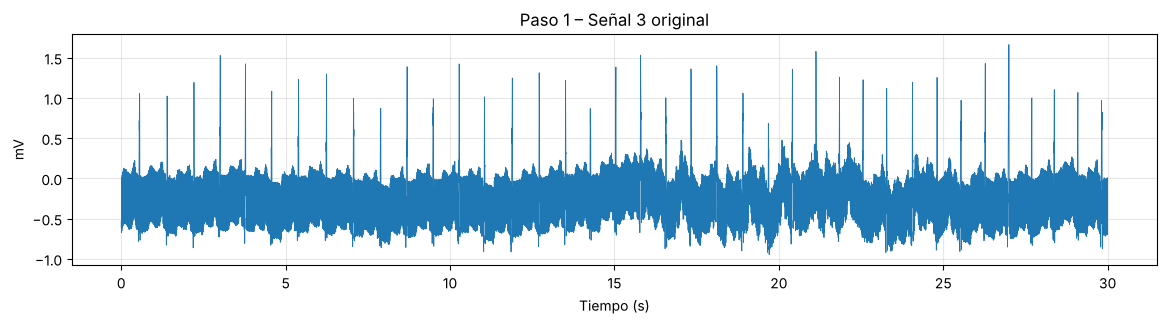

Señal 41: fs = 90 Hz, 2700 muestras, duración = 30.0 s


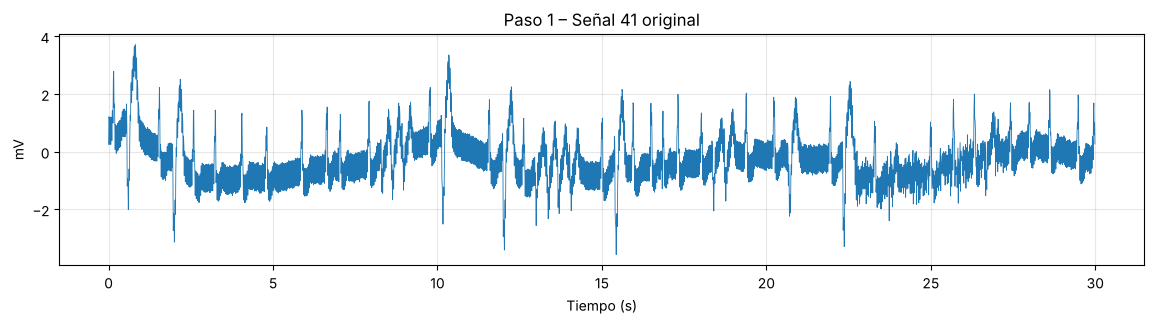

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, filtfilt, find_peaks

S = {}    # aquí guardo los datos y resultados de cada señal: S[número]
for n in SENALES:
    # Leo el archivo de la señal
    datos = pd.read_csv(f"{CARPETA}/senal_{n:02d}.csv")
    t = datos["tiempo_s"].values
    x = datos["ecg_mV"].values
    # Calculo la frecuencia de muestreo con el paso de tiempo
    fs = round(1 / (t[1] - t[0]))
    S[n] = {"t": t, "x": x, "fs": fs}
    print(f"Señal {n}: fs = {fs} Hz, {len(x)} muestras, duración = {len(x)/fs:.1f} s")

    plt.figure(figsize=(14, 3))
    plt.plot(t, x, linewidth=0.6)
    plt.title(f"Paso 1 – Señal {n} original")
    plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.grid(alpha=0.3)
    plt.show()

## **Paso 2 – Espectro de magnitud (FFT): ¿qué ruido tiene cada señal?**
**Qué hace:** calculo la Transformada Rápida de Fourier (FFT) para ver la señal en frecuencia. Antes resto la media para que el valor constante no tape lo demás.

**Qué muestra y cómo lo leo:**
- **Pico angosto en 60 Hz** (y en 120 Hz) → ruido de la **red eléctrica**.
- **Energía cerca de 0 Hz (< 0.5 Hz)** → **deriva de línea base** (respiración, movimiento).
- **Piso alto en frecuencias altas** → **ruido muscular**.
- **Si $f_s = 90$ Hz:** la red de 60 Hz no cabe, porque lo máximo que se puede representar es $f_s/2 = 45$ Hz (teorema de Nyquist). Aparece "doblada" en $|60-90| = 30$ Hz: eso es **aliasing**.

Calculo dónde debe aparecer la red con la fórmula del aliasing: $f_a = |f_0 - k f_s|$, con $k$ el entero más cercano a $f_0/f_s$.

Señal 3: la red eléctrica debe aparecer en [60, 120] Hz


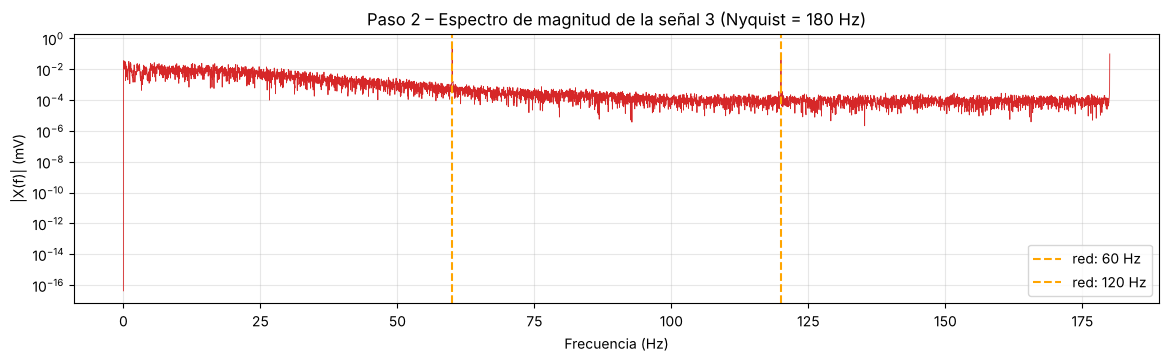

Señal 41: la red eléctrica debe aparecer en [30] Hz


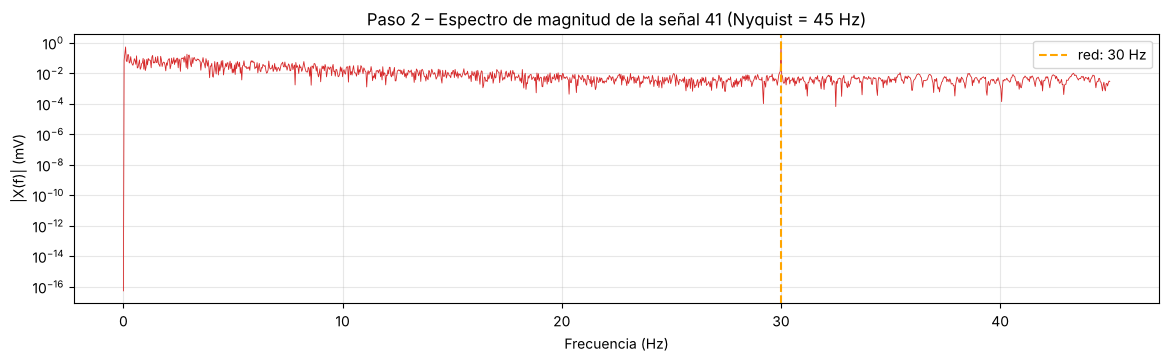

In [3]:
for n in SENALES:
    x, fs = S[n]["x"], S[n]["fs"]
    N = len(x)
    # Calculo la FFT (solo frecuencias positivas) y la normalizo para leer la amplitud en mV
    X = np.abs(np.fft.rfft(x - np.mean(x))) * 2 / N
    f = np.fft.rfftfreq(N, 1 / fs)

    # Decido dónde está la red: en 60 y 120 Hz si caben; si no, en su frecuencia alias
    if fs > 2 * 120:
        red = [60, 120]
    else:
        red = [abs(60 - fs * round(60 / fs))]
    S[n].update({"N": N, "f": f, "X": X, "red": red})
    print(f"Señal {n}: la red eléctrica debe aparecer en {red} Hz")

    plt.figure(figsize=(14, 3.5))
    plt.plot(f, X, linewidth=0.6, color="tab:red")
    for fr in red:
        plt.axvline(fr, color="orange", linestyle="--", label=f"red: {fr} Hz")
    plt.title(f"Paso 2 – Espectro de magnitud de la señal {n} (Nyquist = {fs/2:.0f} Hz)")
    plt.xlabel("Frecuencia (Hz)"); plt.ylabel("|X(f)| (mV)"); plt.yscale("log")
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

## **Paso 3 – Filtro notch: quitar la red eléctrica**
**Qué hace:** aplico un filtro **notch** (rechaza-banda muy angosto) en cada frecuencia de red encontrada en el Paso 2. Tiene un **cero** justo en esa frecuencia, que la elimina, y deja pasar casi todo lo demás. Uso un factor de calidad $Q = 30$, así que solo quito una banda de $f_0/Q$ = 2 Hz alrededor de 60 Hz.

Lo aplico con `filtfilt`, que filtra hacia adelante y hacia atrás. Así el filtro **no retrasa** la señal y los picos R quedan en su lugar.

**Qué muestra:** el espectro de cada señal antes y después. El pico de la red debe desaparecer.

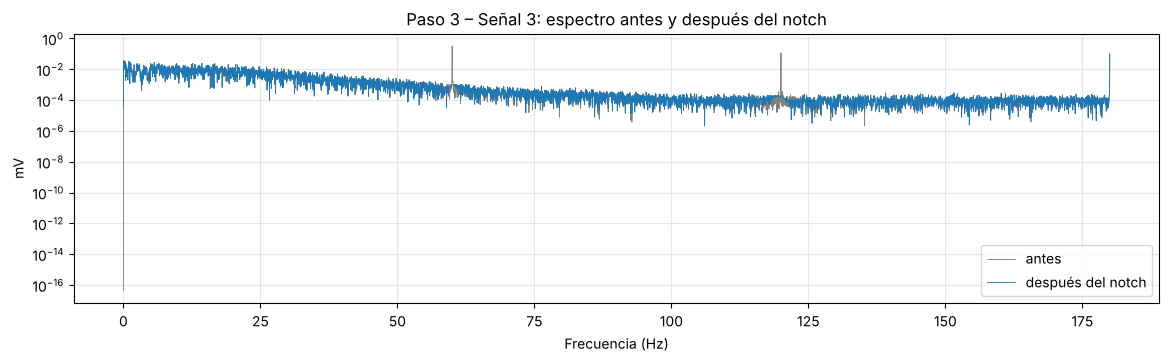

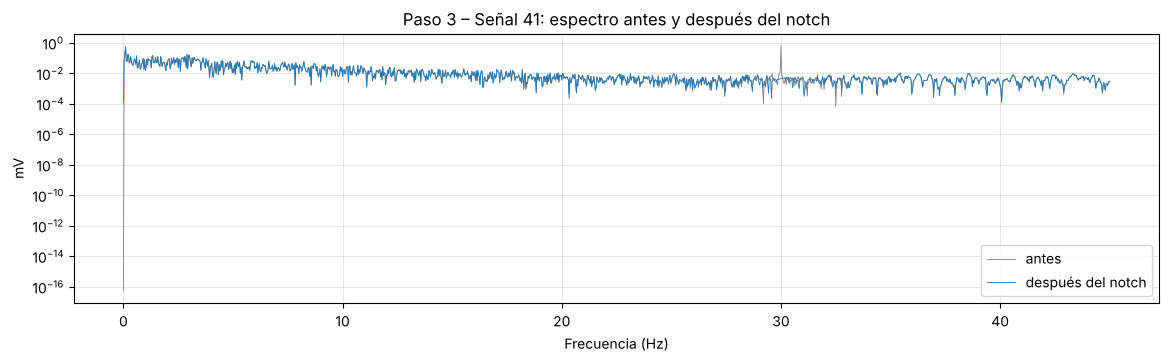

In [4]:
for n in SENALES:
    x, fs, red = S[n]["x"], S[n]["fs"], S[n]["red"]
    x_notch = x - np.mean(x)
    for fr in red:
        b, a = iirnotch(fr, 30, fs)          # diseño el notch en la frecuencia de la red
        x_notch = filtfilt(b, a, x_notch)    # lo aplico sin desfase
    S[n]["x_notch"] = x_notch

    X_notch = np.abs(np.fft.rfft(x_notch)) * 2 / S[n]["N"]
    plt.figure(figsize=(14, 3.5))
    plt.plot(S[n]["f"], S[n]["X"], linewidth=0.6, color="gray", label="antes")
    plt.plot(S[n]["f"], X_notch, linewidth=0.6, color="tab:blue", label="después del notch")
    plt.title(f"Paso 3 – Señal {n}: espectro antes y después del notch")
    plt.xlabel("Frecuencia (Hz)"); plt.ylabel("mV"); plt.yscale("log"); plt.legend(); plt.grid(alpha=0.3)
    plt.show()

## **Paso 4 – Filtro pasa-banda de 5 a 15 Hz**
**Qué hace:** aplico un filtro **Butterworth pasa-banda** de 5 a 15 Hz, también con `filtfilt`. Escojo esa banda porque ahí está la mayor parte de la energía del complejo QRS (Pan y Tompkins, 1985). Con un solo filtro elimino a la vez:
- la **deriva de línea base** (< 0.5 Hz),
- el **ruido muscular** (frecuencias altas),
- y buena parte de las **ondas P y T**, que son más lentas que el QRS.

**Qué muestra:** 5 segundos de cada señal, original y filtrada. En la filtrada la línea base queda plana y los QRS resaltan.

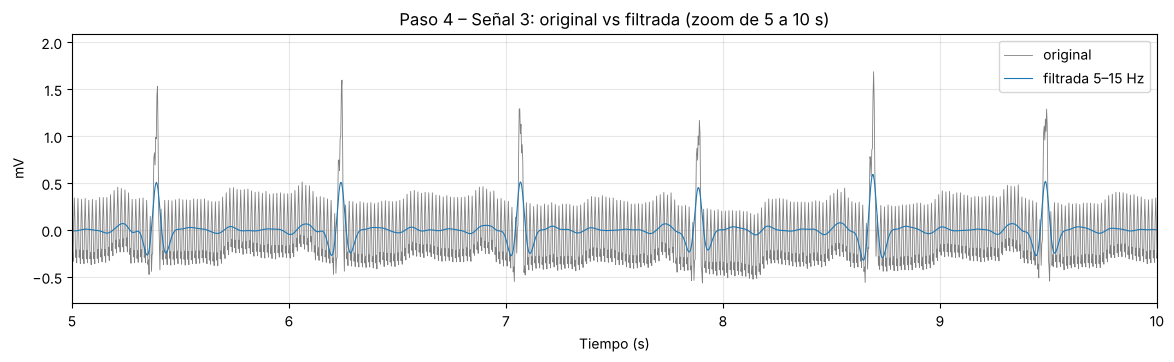

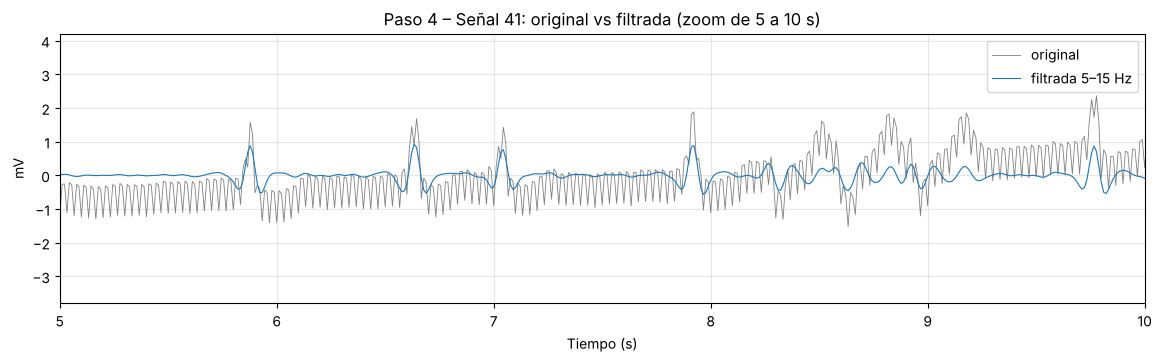

In [5]:
for n in SENALES:
    t, x, fs = S[n]["t"], S[n]["x"], S[n]["fs"]
    b, a = butter(2, [5 / (fs / 2), 15 / (fs / 2)], btype="band")   # normalizo los cortes con fs/2
    x_filtrada = filtfilt(b, a, S[n]["x_notch"])
    S[n]["x_filtrada"] = x_filtrada

    plt.figure(figsize=(14, 3.5))
    plt.plot(t, x - np.mean(x), linewidth=0.6, color="gray", label="original")
    plt.plot(t, x_filtrada, linewidth=0.8, color="tab:blue", label="filtrada 5–15 Hz")
    plt.xlim(5, 10)
    plt.title(f"Paso 4 – Señal {n}: original vs filtrada (zoom de 5 a 10 s)")
    plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend(); plt.grid(alpha=0.3)
    plt.show()

## **Paso 5 – Derivada, cuadrado e integración (Pan y Tompkins)**
**Qué hace:**
1. **Derivada:** mide la pendiente. El QRS es la parte más empinada del latido, así que resalta.
2. **Cuadrado:** vuelve todo positivo y agranda las pendientes grandes. Por eso el método funciona **aunque el QRS esté invertido**.
3. **Integración en una ventana móvil de 150 ms:** suaviza y deja **una sola "joroba" por latido**.

**Qué muestra:** la señal integrada de cada señal. Cada joroba es un latido.

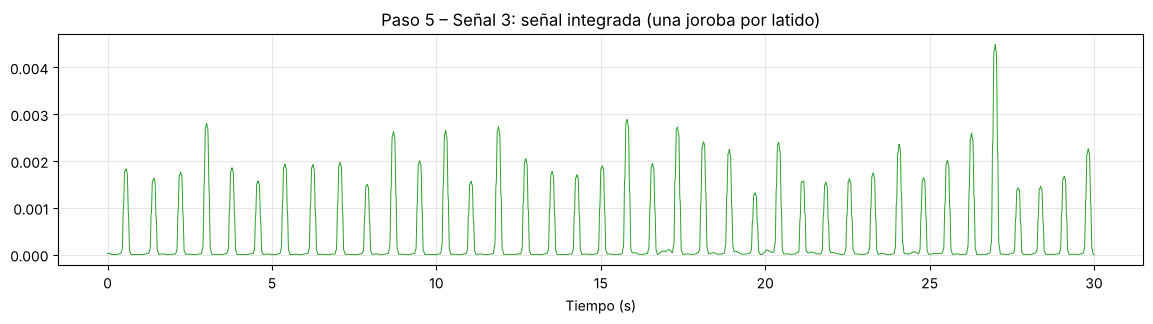

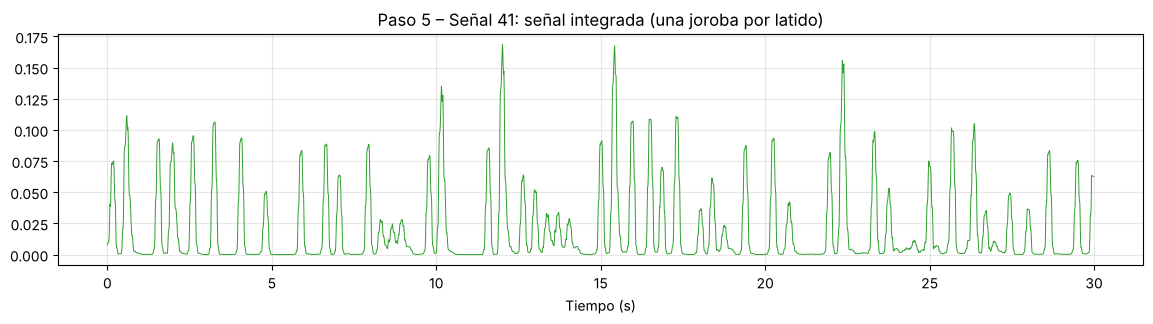

In [6]:
for n in SENALES:
    t, fs, x_filtrada = S[n]["t"], S[n]["fs"], S[n]["x_filtrada"]
    derivada = np.diff(x_filtrada, prepend=x_filtrada[0])     # 1) calculo la pendiente
    cuadrado = derivada ** 2                                   # 2) la elevo al cuadrado
    ventana = int(0.150 * fs)                                  # 3) paso 150 ms a muestras e integro
    integrada = np.convolve(cuadrado, np.ones(ventana) / ventana, mode="same")
    S[n]["integrada"] = integrada

    plt.figure(figsize=(14, 3))
    plt.plot(t, integrada, linewidth=0.7, color="tab:green")
    plt.title(f"Paso 5 – Señal {n}: señal integrada (una joroba por latido)")
    plt.xlabel("Tiempo (s)"); plt.grid(alpha=0.3)
    plt.show()

## **Paso 6 – Detectar los picos R**
**Qué hace:** busco los máximos de la señal integrada con tres reglas sencillas:
1. **Distancia mínima de 0.3 s** entre latidos (más de 200 latidos por minuto no es posible en reposo). Esto también evita contar la onda T del mismo latido.
2. **Umbral:** un pico cuenta como latido si supera el **30 %** de la altura típica de los latidos. Esa altura típica es la mediana de la mitad más alta de los picos, para que un artefacto muy grande no la afecte.
3. **Búsqueda de latidos perdidos:** si entre dos latidos pasa más de **1.66 veces** el RR típico, busco en ese hueco el pico más alto con un umbral más bajo (10 %). Esta idea es el *searchback* de Pan y Tompkins.

Al final descarto los picos de los primeros y últimos 0.1 s, donde los filtros tienen efectos de borde, y muevo cada detección al punto de mayor amplitud de la señal filtrada (±75 ms), porque la integración corre un poco la joroba respecto al pico R real.

**Qué muestra:** cada señal filtrada con sus picos R marcados en rojo.

Señal 3: 39 latidos detectados


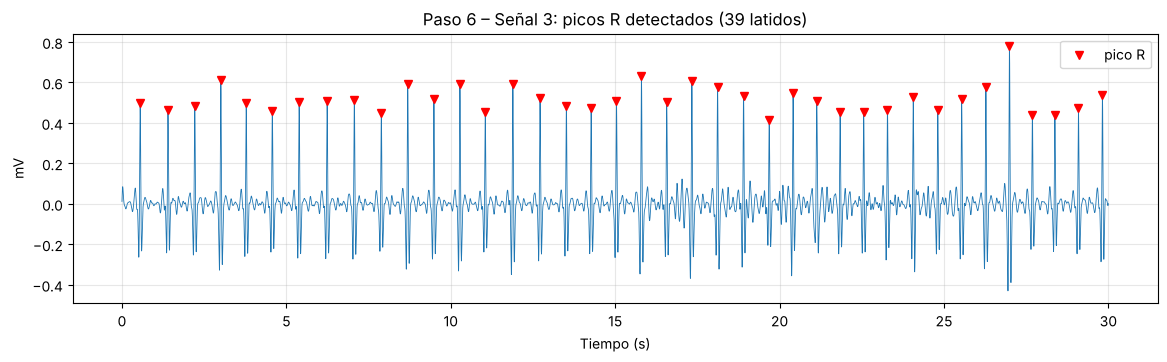

Señal 41: 47 latidos detectados


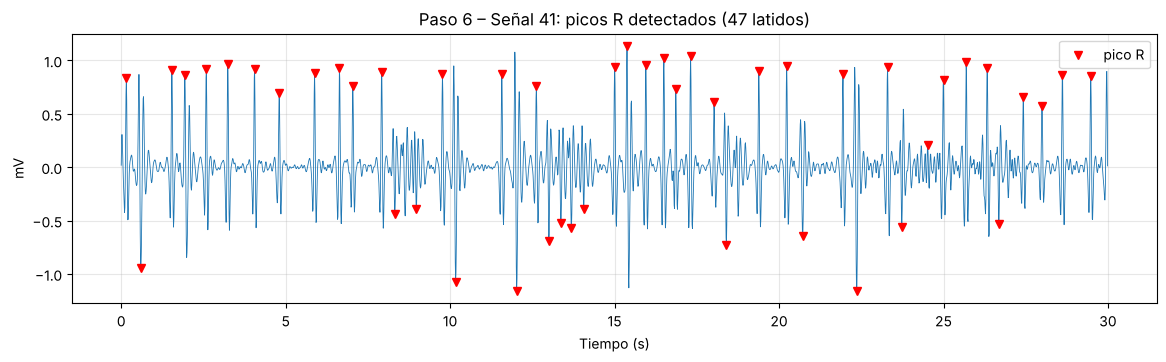

In [7]:
DISTANCIA = 0.3      # segundos entre latidos como mínimo
UMBRAL = 0.30        # 30 % de la altura típica
FACTOR_HUECO = 1.66  # para buscar latidos perdidos (Pan y Tompkins)

for n in SENALES:
    t, fs, N = S[n]["t"], S[n]["fs"], S[n]["N"]
    integrada, x_filtrada = S[n]["integrada"], S[n]["x_filtrada"]

    # 1) Busco todos los candidatos separados al menos 0.3 s
    candidatos, _ = find_peaks(integrada, distance=int(DISTANCIA * fs))

    # 2) Calculo la altura típica y me quedo con los candidatos que pasan el 30 %
    alturas = np.sort(integrada[candidatos])[::-1]
    altura_tipica = np.median(alturas[: len(alturas) // 2])
    picos = list(candidatos[integrada[candidatos] > UMBRAL * altura_tipica])

    # 3) Si encuentro un hueco muy largo, busco el latido perdido con un umbral más bajo
    rr_tipico = np.median(np.diff(picos))
    k = 0
    while k < len(picos) - 1:
        if picos[k + 1] - picos[k] > FACTOR_HUECO * rr_tipico:
            en_hueco = [c for c in candidatos
                        if picos[k] + DISTANCIA * fs < c < picos[k + 1] - DISTANCIA * fs
                        and integrada[c] > 0.10 * altura_tipica]
            if en_hueco:
                picos.insert(k + 1, max(en_hueco, key=lambda c: integrada[c]))
                continue                   # vuelvo a revisar el mismo tramo
        k += 1

    # Quito los picos pegados a los bordes
    picos = np.array(picos)
    picos = picos[(picos > 0.1 * fs) & (picos < N - 0.1 * fs)]

    # Corrijo la posición: la integración corre la joroba unos milisegundos, así que
    # busco el punto de mayor amplitud de la señal filtrada a ±75 ms de cada joroba
    v = int(0.075 * fs)
    picos = np.array([p - v + np.argmax(np.abs(x_filtrada[p - v: p + v])) for p in picos])
    S[n]["picos"] = picos
    print(f"Señal {n}: {len(picos)} latidos detectados")

    plt.figure(figsize=(14, 3.5))
    plt.plot(t, x_filtrada, linewidth=0.6)
    plt.plot(t[picos], x_filtrada[picos], "rv", label="pico R")
    plt.title(f"Paso 6 – Señal {n}: picos R detectados ({len(picos)} latidos)")
    plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend(); plt.grid(alpha=0.3)
    plt.show()

## **Paso 7 – Intervalos RR y frecuencia cardiaca**
**Qué hace:** calculo el tiempo entre picos consecutivos (intervalos RR), su promedio y la frecuencia cardiaca:
$$FC = \frac{60}{\overline{RR}}$$

**Qué muestra:** el **tacograma** de cada señal (cada RR en el tiempo) y, al final, una **tabla con la FC de todas las señales elegidas**. Si los puntos del tacograma están casi en línea, el ritmo es regular. Si saltan mucho, hay latidos adelantados (extrasístoles) o pausas.

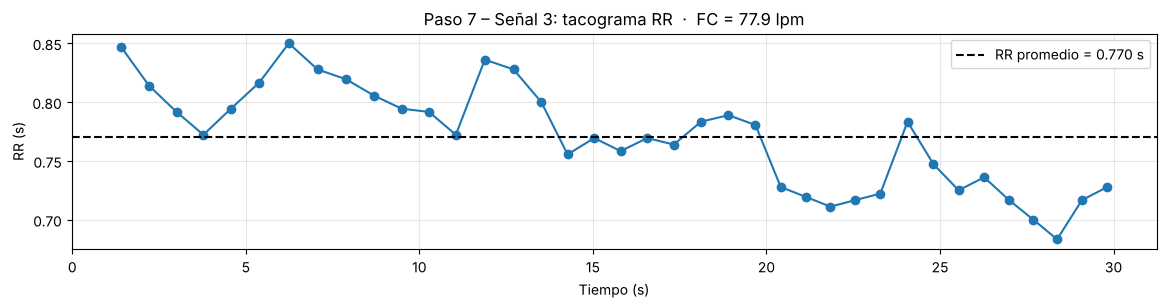

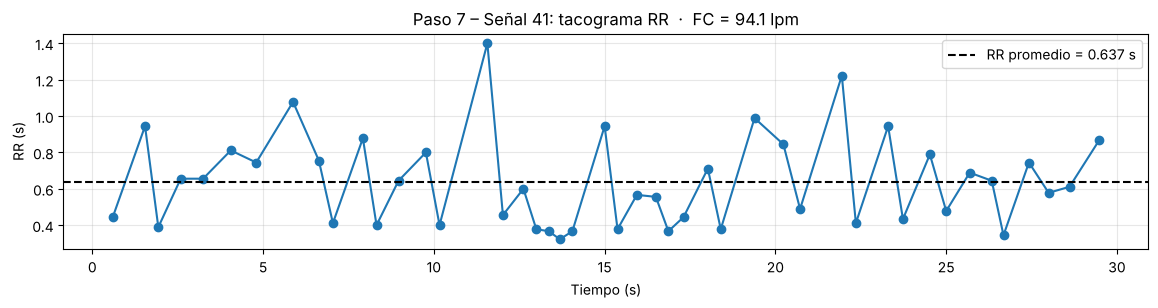

RESULTADO FINAL
 senal  fs_Hz  latidos  RR_promedio_s  FC_lpm
     3    360       39          0.770    77.9
    41     90       47          0.637    94.1


In [8]:
tabla = []
for n in SENALES:
    t, fs, picos = S[n]["t"], S[n]["fs"], S[n]["picos"]
    RR = np.diff(picos) / fs                 # calculo los intervalos RR en segundos
    RR_promedio = np.mean(RR)
    FC = 60 / RR_promedio                    # aplico la fórmula de la FC
    tabla.append({"senal": n, "fs_Hz": fs, "latidos": len(picos),
                  "RR_promedio_s": round(RR_promedio, 3), "FC_lpm": round(FC, 1)})

    plt.figure(figsize=(14, 2.8))
    plt.plot(t[picos[1:]], RR, "o-")
    plt.axhline(RR_promedio, color="k", linestyle="--", label=f"RR promedio = {RR_promedio:.3f} s")
    plt.title(f"Paso 7 – Señal {n}: tacograma RR  ·  FC = {FC:.1f} lpm")
    plt.xlabel("Tiempo (s)"); plt.ylabel("RR (s)"); plt.legend(); plt.grid(alpha=0.3)
    plt.show()

print("RESULTADO FINAL")
print(pd.DataFrame(tabla).to_string(index=False))

## **Paso 8 (opcional) – Las 48 señales y el archivo `resultados_g08.csv`**
**Qué hace:** repito exactamente los Pasos 1 a 7 para las 48 señales dentro de una función y guardo el archivo de entrega con las columnas `senal` y `FC_lpm`.

**Qué muestra:** la tabla con la FC de todas las señales. Este paso no hace falta para la comprobación de una sola señal.

In [9]:
def calcular_fc(numero):
    # Hago lo mismo que en los Pasos 1 a 7, pero sin gráficas, para la señal 'numero'
    d = pd.read_csv(f"{CARPETA}/senal_{numero:02d}.csv")
    tt, xx = d["tiempo_s"].values, d["ecg_mV"].values
    fs_ = round(1 / (tt[1] - tt[0]))
    red = [60, 120] if fs_ > 2 * 120 else [abs(60 - fs_ * round(60 / fs_))]
    y = xx - np.mean(xx)
    for fr in red:                                        # Paso 3: aplico el notch
        b, a = iirnotch(fr, 30, fs_); y = filtfilt(b, a, y)
    b, a = butter(2, [5 / (fs_ / 2), 15 / (fs_ / 2)], btype="band")
    y = filtfilt(b, a, y)                                 # Paso 4: aplico el pasa-banda
    w = int(0.150 * fs_)                                  # Paso 5: derivo, elevo al cuadrado e integro
    integ = np.convolve(np.diff(y, prepend=y[0]) ** 2, np.ones(w) / w, mode="same")
    cand, _ = find_peaks(integ, distance=int(DISTANCIA * fs_))    # Paso 6: detecto los picos
    alt = np.median(np.sort(integ[cand])[::-1][: len(cand) // 2])
    p = list(cand[integ[cand] > UMBRAL * alt])
    rr_t = np.median(np.diff(p)); k = 0
    while k < len(p) - 1:
        if p[k + 1] - p[k] > FACTOR_HUECO * rr_t:
            h = [c for c in cand if p[k] + DISTANCIA * fs_ < c < p[k + 1] - DISTANCIA * fs_ and integ[c] > 0.10 * alt]
            if h:
                p.insert(k + 1, max(h, key=lambda c: integ[c])); continue
        k += 1
    p = np.array(p); p = p[(p > 0.1 * fs_) & (p < len(y) - 0.1 * fs_)]
    v = int(0.075 * fs_)
    p = np.array([q - v + np.argmax(np.abs(y[q - v: q + v])) for q in p])
    return 60 / np.mean(np.diff(p) / fs_)                 # Paso 7: calculo la FC

resultados = pd.DataFrame({"senal": [f"senal_{i:02d}" for i in range(1, 49)],
                           "FC_lpm": [round(calcular_fc(i), 2) for i in range(1, 49)]})
resultados.to_csv("resultados_g08.csv", index=False)
print("Archivo resultados_g08.csv guardado.")
print(resultados.to_string(index=False))

Archivo resultados_g08.csv guardado.
   senal  FC_lpm
senal_01   85.06
senal_02   75.55
senal_03   77.91
senal_04   63.75
senal_05   84.17
senal_06   52.81
senal_07   65.21
senal_08  107.27
senal_09   79.20
senal_10   86.20
senal_11   51.48
senal_12   71.39
senal_13   85.19
senal_14   65.47
senal_15   56.85
senal_16   58.15
senal_17   90.49
senal_18   73.72
senal_19   62.89
senal_20   87.48
senal_21   55.78
senal_22  113.75
senal_23  105.11
senal_24   61.58
senal_25   72.97
senal_26   50.89
senal_27   89.20
senal_28   59.98
senal_29   68.65
senal_30   87.27
senal_31   79.47
senal_32   63.91
senal_33   80.13
senal_34   58.13
senal_35   74.34
senal_36  109.46
senal_37   70.87
senal_38   82.77
senal_39   41.67
senal_40   84.22
senal_41   94.13
senal_42  101.60
senal_43   70.83
senal_44   69.17
senal_45   83.61
senal_46   89.03
senal_47   90.11
senal_48   66.69


## **Referencias fundamentales**
1. **Pan, J. y Tompkins, W. J.** (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering*, BME-32(3), 230–236. DOI: [10.1109/TBME.1985.325532](https://doi.org/10.1109/TBME.1985.325532) — **idea base**: banda 5–15 Hz, derivada, cuadrado, integración de 150 ms, umbral y búsqueda de latidos perdidos.
2. **Oppenheim, A. V. y Schafer, R. W.** (2010). *Discrete-Time Signal Processing* (3.ª ed.). Pearson. Cap. 4 (muestreo y aliasing), Cap. 7 (filtros Butterworth), Cap. 8–9 (DFT y FFT).
3. **Proakis, J. G. y Manolakis, D. G.** (2007). *Digital Signal Processing: Principles, Algorithms, and Applications* (4.ª ed.). Pearson. Sec. 1.4 (frecuencia alias) y Sec. 5.4 (filtros notch).